# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Isi Nama Kalian | Isi NRP Kalian |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal


In [1]:
# Import library yang dibutuhkan.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [ ]:
# Load dataset.
# Download dataset dari Kaggle dan baca file CSV (fallback ke insurance.csv di folder yang sama).
try:
    dataset_path = kagglehub.dataset_download("mirichoi0218/insurance")
    df = pd.read_csv(os.path.join(dataset_path, "insurance.csv"))
except Exception:
    df = pd.read_csv("insurance.csv")


In [ ]:
# Tampilkan beberapa baris pertama dataset.
df.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
# Tampilkan informasi dataset.
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [ ]:
# Periksa missing value.
df.isnull().sum()


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [6]:
# Tampilkan statistik deskriptif fitur numerik.
df.describe().transpose()


,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


In [7]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal.
for col in df.select_dtypes(exclude=['number']).columns:
    print(f"\n{col}:")
    print(df[col].value_counts())



sex:
sex
male      676
female    662
Name: count, dtype: int64

smoker:
smoker
no     1064
yes     274
Name: count, dtype: int64

region:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.

- Distribusi target `charges`
- Hubungan antara `smoker` dan rata-rata `charges`
- Korelasi antar fitur numerik


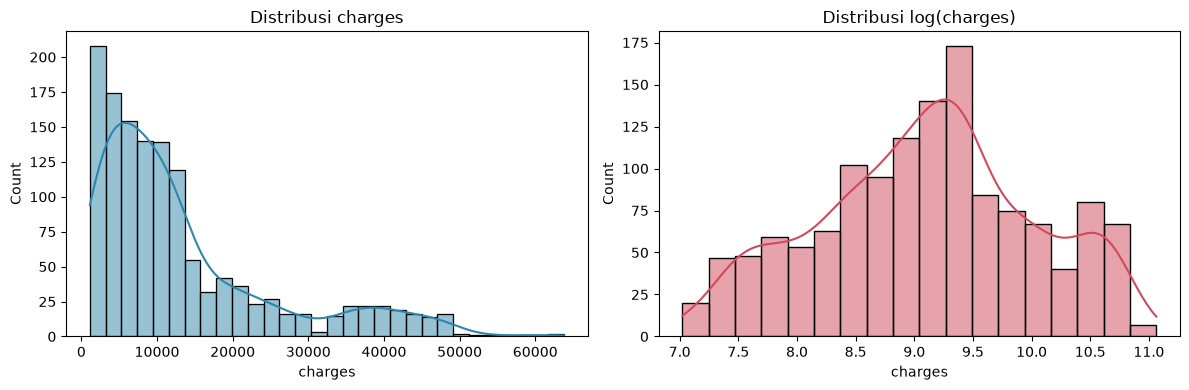

Skewness charges: 1.516


In [ ]:
# EDA 1: distribusi target `charges` (terlihat right-skewed)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["charges"], kde=True, ax=axes[0], color="#2E86AB")
axes[0].set_title("Distribusi charges")
sns.histplot(np.log(df["charges"]), kde=True, ax=axes[1], color="#D1495B")
axes[1].set_title("Distribusi log(charges)")
plt.tight_layout()
plt.show()
print("Skewness charges:", round(df["charges"].skew(), 3))


,mean,median,count
smoker,,,
no,8434.3,7345.4,1064
yes,32050.2,34456.3,274


/tmp/ipykernel_109114/4034162913.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="smoker", y="charges", estimator="mean", errorbar=None,
/tmp/ipykernel_109114/4034162913.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="smoker", y="charges", palette=["#4C9F70", "#D1495B"])


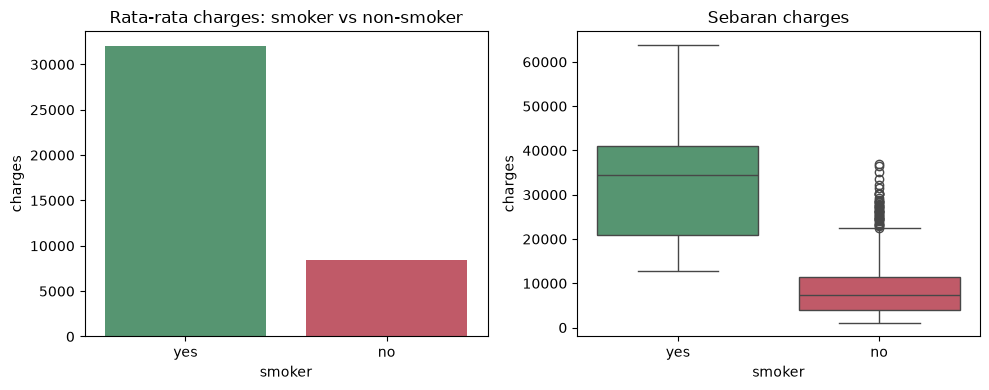

In [9]:
# EDA 2: hubungan `smoker` dengan rata-rata `charges`
smoker_stats = df.groupby("smoker")["charges"].agg(["mean", "median", "count"]).round(1)
display(smoker_stats)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.barplot(data=df, x="smoker", y="charges", estimator="mean", errorbar=None,
            palette=["#4C9F70", "#D1495B"])
plt.title("Rata-rata charges: smoker vs non-smoker")
plt.subplot(1, 2, 2)
sns.boxplot(data=df, x="smoker", y="charges", palette=["#4C9F70", "#D1495B"])
plt.title("Sebaran charges")
plt.tight_layout()
plt.show()


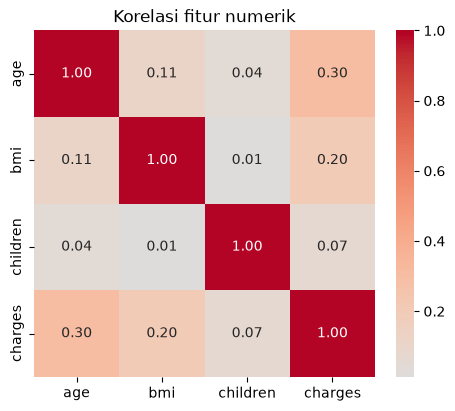

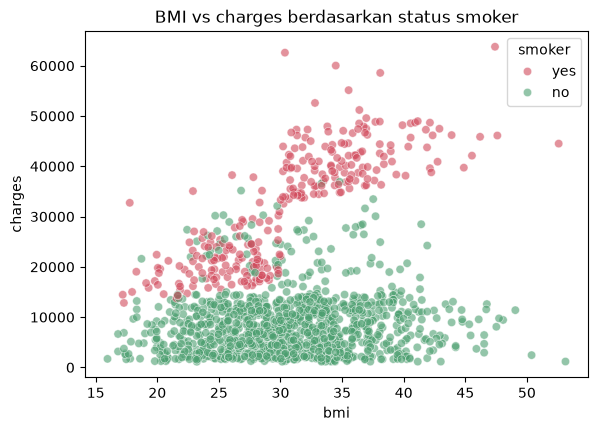

In [10]:
# EDA 3: korelasi antar fitur numerik
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Korelasi fitur numerik")
plt.show()

# Tambahan: apakah efek BMI terhadap charges berbeda untuk smoker dan non-smoker (interaksi)?
plt.figure(figsize=(6.5, 4.5))
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker",
                palette={"no": "#4C9F70", "yes": "#D1495B"}, alpha=0.6)
plt.title("BMI vs charges berdasarkan status smoker")
plt.show()


# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.


In [11]:
# Pisahkan fitur (X) dan target (y).
X = df.drop(columns=['charges'])
y = df['charges']


In [12]:
# Identifikasi kolom numerik dan kategorikal.
numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(exclude=['number']).columns.tolist()
print('Fitur numerik:', numeric_features)
print('Fitur kategorikal:', categorical_features)


Fitur numerik: ['age', 'bmi', 'children']
Fitur kategorikal: ['sex', 'smoker', 'region']


In [13]:
# Bagi data menjadi train set dan test set.
# Test set hanya dipakai untuk evaluasi akhir; tuning hyperparameter memakai cross-validation pada train set.
RANDOM_STATE = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (1070, 6) | Test: (268, 6)


In [14]:
# Buat preprocessing untuk fitur numerik dan kategorikal.
try:
    onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', onehot, categorical_features)
    ],
    remainder='drop'
)

tree_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('cat', onehot, categorical_features)
    ],
    remainder='drop'
)


In [15]:
# Skema cross-validation untuk tuning hyperparameter (hanya memakai train set)
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = "neg_root_mean_squared_error"

def run_grid(estimator, param_grid):
    """GridSearchCV dengan CV 5-fold pada train set, menampilkan 5 kombinasi terbaik."""
    grid = GridSearchCV(estimator, param_grid, cv=CV, scoring=SCORING, n_jobs=-1)
    grid.fit(X_train, y_train)
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score"]
    res = res[cols].copy()
    res["CV RMSE"] = -res.pop("mean_test_score")
    print("Best params:", grid.best_params_, "| CV RMSE:", round(-grid.best_score_, 2))
    display(res.sort_values("CV RMSE").head(5).round(3))
    return grid


# 3. Eksperimen Model


## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.


In [16]:
# Inisialisasi dan latih Linear Regression.
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the 

In [17]:
# Lakukan prediksi pada test set.
linear_pred = linear_model.predict(X_test)
linear_pred[:5]


array([ 8969.55027444,  7068.74744287, 36858.41091155,  9454.67850053,
       26973.17345656])

## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.


In [18]:
# Tuning degree polynomial dengan cross-validation (degree 1 = Linear Regression biasa)
poly_grid = run_grid(
    Pipeline([
        ('preprocessor', preprocessor),
        ('poly', PolynomialFeatures(include_bias=False)),
        ('model', LinearRegression())
    ]),
    {'poly__degree': [1, 2, 3, 4]}
)
best_degree = poly_grid.best_params_['poly__degree']


Best params: {'poly__degree': 2} | CV RMSE: 4887.28


,param_poly__degree,CV RMSE
1,2,4887.277
2,3,5144.414
0,1,6123.354
3,4,6469.783


In [19]:
# Buat fitur polynomial dan latih model dengan degree terbaik hasil tuning.
poly_model = Pipeline([
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=best_degree, include_bias=False)),
    ('model', LinearRegression())
])

poly_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with 

In [20]:
# Lakukan prediksi pada test set.
poly_pred = poly_model.predict(X_test)
poly_pred[:5]


array([11215.72133573,  6055.22653741, 33306.27444924, 10833.80112228,
       29082.43036144])

## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [21]:
# Tuning alpha Ridge dengan cross-validation
ridge_grid = run_grid(
    Pipeline([('preprocessor', preprocessor), ('model', Ridge())]),
    {'model__alpha': np.logspace(-2, 3, 11)}
)
best_ridge_alpha = ridge_grid.best_params_['model__alpha']


Best params: {'model__alpha': np.float64(0.31622776601683794)} | CV RMSE: 6123.33


,param_model__alpha,CV RMSE
3,0.316,6123.329
2,0.100,6123.344
4,1.000,6123.344
1,0.032,6123.350
0,0.010,6123.353


In [22]:
# Inisialisasi dan latih Ridge Regression dengan alpha terbaik hasil tuning.
ridge_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=best_ridge_alpha))
])

ridge_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the 

In [23]:
# Lakukan prediksi pada test set.
ridge_pred = ridge_model.predict(X_test)
ridge_pred[:5]


array([ 8972.84637621,  7072.19915769, 36837.58719416,  9459.02753933,
       26957.65419452])

## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [24]:
# Tuning alpha Lasso dengan cross-validation
# Catatan: target `charges` berskala puluhan ribu sehingga alpha yang bermakna jauh lebih besar dari 0.01.
lasso_grid = run_grid(
    Pipeline([('preprocessor', preprocessor), ('model', Lasso(max_iter=50000))]),
    {'model__alpha': np.logspace(-2, 3, 11)}
)
best_lasso_alpha = lasso_grid.best_params_['model__alpha']


Best params: {'model__alpha': np.float64(31.622776601683793)} | CV RMSE: 6120.33


,param_model__alpha,CV RMSE
7,31.623,6120.334
6,10.000,6122.000
5,3.162,6122.961
4,1.000,6123.254
3,0.316,6123.301


In [25]:
# Inisialisasi dan latih Lasso Regression dengan alpha terbaik hasil tuning.
lasso_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Lasso(alpha=best_lasso_alpha, max_iter=50000))
])

lasso_model.fit(X_train, y_train)

# Koefisien yang dinolkan oleh Lasso (seleksi fitur)
feature_names = lasso_model.named_steps['preprocessor'].get_feature_names_out()
coef = pd.Series(lasso_model.named_steps['model'].coef_, index=feature_names)
print("Fitur dengan koefisien 0:", list(coef[coef == 0].index))


Fitur dengan koefisien 0: ['cat__sex_female', 'cat__sex_male', 'cat__region_northwest', 'cat__region_southeast']


In [26]:
# Lakukan prediksi pada test set.
lasso_pred = lasso_model.predict(X_test)
lasso_pred[:5]


array([ 8884.45777366,  6995.19740253, 36556.55739642,  9359.83432424,
       26727.47265974])

## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.


In [27]:
# Tuning max_depth dan min_samples_leaf Decision Tree dengan cross-validation
tree_grid = run_grid(
    Pipeline([
        ('preprocessor', tree_preprocessor),
        ('model', DecisionTreeRegressor(random_state=RANDOM_STATE))
    ]),
    {'model__max_depth': [2, 3, 4, 5, 6, 8, 10],
     'model__min_samples_leaf': [1, 5, 10, 20, 40]}
)
best_depth = tree_grid.best_params_['model__max_depth']
best_leaf = tree_grid.best_params_['model__min_samples_leaf']


Best params: {'model__max_depth': 4, 'model__min_samples_leaf': 10} | CV RMSE: 4580.51


,param_model__max_depth,param_model__min_samples_leaf,CV RMSE
12,4,10,4580.513
11,4,5,4588.036
13,4,20,4609.522
18,5,20,4621.749
10,4,1,4636.099


In [28]:
# Inisialisasi dan latih Decision Tree Regressor dengan hyperparameter terbaik hasil tuning.
tree_model = Pipeline([
    ('preprocessor', tree_preprocessor),
    ('model', DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=best_leaf,
                                    random_state=RANDOM_STATE))
])

tree_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the 

In [29]:
# Lakukan prediksi pada test set.
tree_pred = tree_model.predict(X_test)
tree_pred[:5]


array([10662.68286257,  5703.33875202, 27503.00828667, 10662.68286257,
       35031.66093192])

## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.


**Catatan SVR:** `charges` berskala puluhan ribu, sedangkan `epsilon` SVR dihitung pada skala target. Jika target tidak di-scaling, SVR dengan epsilon/C kecil cenderung hanya memprediksi nilai hampir konstan (underfit parah). Karena itu target di-scaling dengan `TransformedTargetRegressor`; prediksi otomatis dikembalikan ke skala asli (dollar) sehingga metrik evaluasi tetap sebanding dengan model lain.


In [30]:
# Tuning SVR (target di-scaling lewat TransformedTargetRegressor)
svr_base = TransformedTargetRegressor(
    regressor=Pipeline([('preprocessor', preprocessor), ('model', SVR(kernel='rbf'))]),
    transformer=StandardScaler()
)
svr_grid = run_grid(
    svr_base,
    {'regressor__model__C': [0.1, 1, 10, 100],
     'regressor__model__epsilon': [0.05, 0.1, 0.2],
     'regressor__model__gamma': ['scale', 0.05, 0.2]}
)
svr_best = {k.split('__')[-1]: v for k, v in svr_grid.best_params_.items()}


Best params: {'regressor__model__C': 10, 'regressor__model__epsilon': 0.1, 'regressor__model__gamma': 0.05} | CV RMSE: 4794.54


,param_regressor__model__C,param_regressor__model__epsilon,param_regressor__model__gamma,CV RMSE
22,10.0,0.10,0.05,4794.540
25,10.0,0.20,0.05,4808.358
19,10.0,0.05,0.05,4845.892
12,1.0,0.10,scale,4846.192
13,1.0,0.10,0.05,4847.143


In [31]:
# Inisialisasi dan latih SVR dengan hyperparameter terbaik hasil tuning.
svr_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ('preprocessor', preprocessor),
        ('model', SVR(kernel='rbf', C=svr_best['C'], epsilon=svr_best['epsilon'],
                      gamma=svr_best['gamma']))
    ]),
    transformer=StandardScaler()
)

svr_model.fit(X_train, y_train)


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...gamma=0.05))])
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",StandardScaler()
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",None
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,6
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...gamma=0.05))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,StandardScaler,StandardScaler()
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"


In [32]:
# Lakukan prediksi pada test set.
svr_pred = svr_model.predict(X_test)
svr_pred[:5]


array([ 9916.86754311,  6333.546179  , 30465.11391733,  9821.29028225,
       27403.9908176 ])

# 4. Evaluasi Model


In [33]:
# Hitung MAE, MSE, RMSE, dan R² (test set) untuk setiap model,
# plus CV RMSE pada train set sebagai ukuran yang lebih stabil.
# Sajikan hasil dalam satu tabel perbandingan.

def evaluate_model(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    }

models = {
    'Linear Regression': linear_model,
    'Polynomial Regression': poly_model,
    'Ridge Regression': ridge_model,
    'Lasso Regression': lasso_model,
    'Decision Tree Regressor': tree_model,
    'SVR': svr_model,
}

model_predictions = {
    'Linear Regression': linear_pred,
    'Polynomial Regression': poly_pred,
    'Ridge Regression': ridge_pred,
    'Lasso Regression': lasso_pred,
    'Decision Tree Regressor': tree_pred,
    'SVR': svr_pred,
}

results = []
for model_name, pred in model_predictions.items():
    metrics = evaluate_model(y_test, pred)
    cv_rmse = -cross_val_score(models[model_name], X_train, y_train,
                               cv=CV, scoring=SCORING, n_jobs=-1).mean()
    results.append({'Model': model_name, **metrics, 'CV_RMSE (train)': cv_rmse})

comparison_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
comparison_df


,Model,MAE,MSE,RMSE,R2,CV_RMSE (train)
0,SVR,2366.120978,2.058406e+07,4536.965634,0.867412,4794.540414
1,Polynomial Regression,2729.500134,2.071281e+07,4551.132385,0.866583,4887.276761
2,Decision Tree Regressor,2697.765431,2.109348e+07,4592.764310,0.864131,4580.513089
3,Linear Regression,4181.194474,3.359692e+07,5796.284659,0.783593,6123.353823
4,Ridge Regression,4182.990294,3.360415e+07,5796.908393,0.783546,6123.328851
5,Lasso Regression,4206.506719,3.387038e+07,5819.826562,0.781832,6120.334278


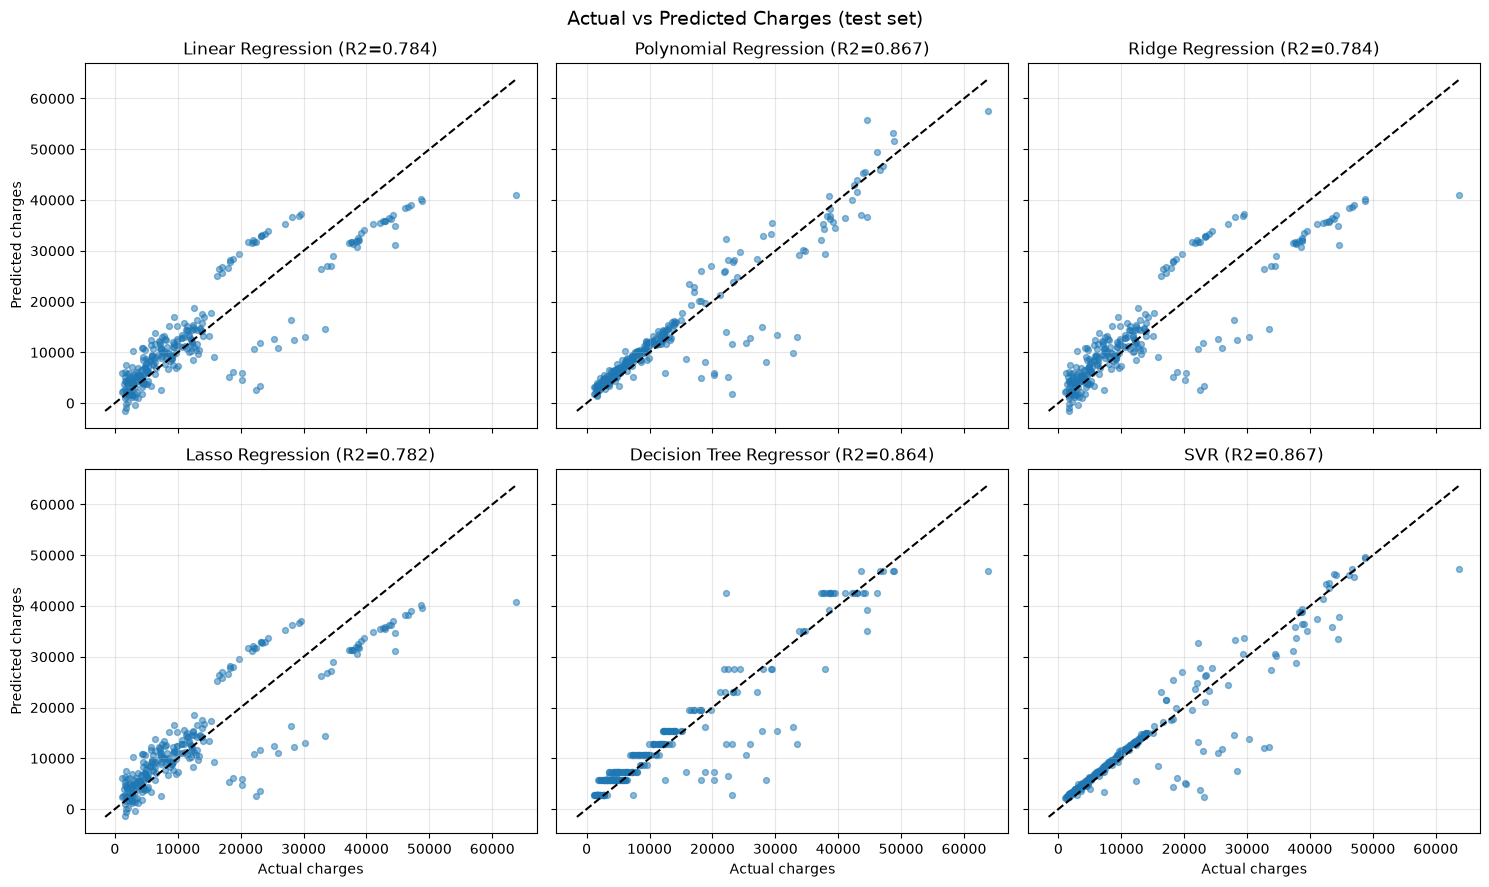

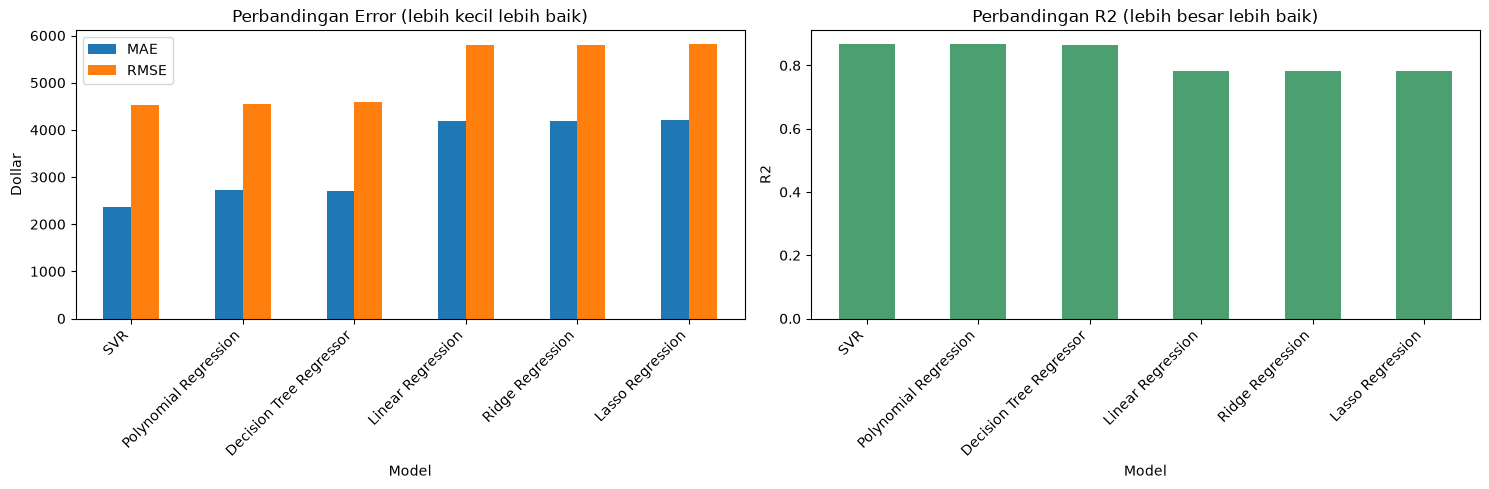

In [34]:
# Visualisasi perbandingan nilai aktual dan prediksi (satu panel per model)
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
lims = [min(y_test.min(), *(p.min() for p in model_predictions.values())),
        max(y_test.max(), *(p.max() for p in model_predictions.values()))]

for ax, (model_name, pred) in zip(axes.ravel(), model_predictions.items()):
    ax.scatter(y_test, pred, alpha=0.5, s=18)
    ax.plot(lims, lims, 'k--', linewidth=1.5)
    r2 = r2_score(y_test, pred)
    ax.set_title(f"{model_name} (R2={r2:.3f})")
    ax.grid(True, alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel('Actual charges')
for ax in axes[:, 0]:
    ax.set_ylabel('Predicted charges')
plt.suptitle('Actual vs Predicted Charges (test set)', fontsize=14)
plt.tight_layout()
plt.show()

# Metrik error (skala dollar) dan R2 digambar terpisah karena skalanya berbeda jauh
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
comparison_df.plot(kind='bar', x='Model', y=['MAE', 'RMSE'], ax=axes[0],
                   title='Perbandingan Error (lebih kecil lebih baik)')
axes[0].set_ylabel('Dollar')
comparison_df.plot(kind='bar', x='Model', y='R2', ax=axes[1], color='#4C9F70', legend=False,
                   title='Perbandingan R2 (lebih besar lebih baik)')
axes[1].set_ylabel('R2')
for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
plt.show()


# 5. Analisis
Model SVR secara konsisten mendominasi split validasi di metrik MAE, MSE, RMSE, dan R2, tetapi memiliki nilai RMSE yang lebih tinggi daripada DecisionTreeRegressor ketika dilakukan cross-validation. Sementara itu, model LassoRegression memiliki nilai MAE, MSE, RMSE, dan R2 terburuk di antara semua model, tetapi memiliki nilai RMSE cross-validation yang sedikit lebih baik daripada LinearRegression dan RidgeRegression.

# 6. Kesimpulan dan Saran
### Kesimpulan
Metrik evaluasi model regresi, seperti MAE, MSE, RMSE, dan R2, menghasilkan skor evaluasi hanya pada split tersebut. Tanpa cross-validation, skor metrik menjadi lebih bias terhadap split yang sedang dilakukan saat ini, menjadikan nilai kurang representatif terhadap performa model yang lebih aktual. 

### Saran
ElasticNet